In [2]:
pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:


# Load the dataframe that was saved in extraction.ipynb
# (makes df available / "global" across notebooks)
df = pd.read_parquet("nhis_data.parquet")
df.shape

(40989, 18)

In [5]:
print(df['GOTSTAMPFAM'].value_counts())

GOTSTAMPFAM
10    34276
21     5122
80     1387
70      136
90       68
Name: count, dtype: Int64


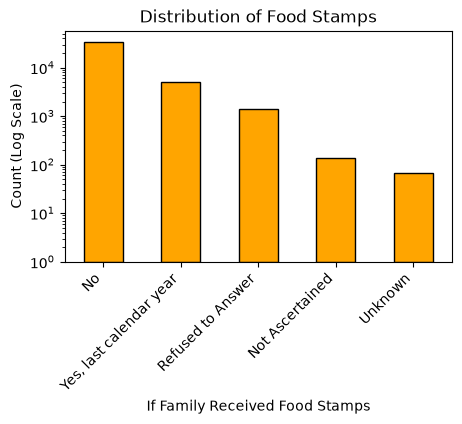

In [6]:
plt.figure(figsize=(5,3))
df['GOTSTAMPFAM'].value_counts().plot.bar(log=True,color='orange',edgecolor='black')
plt.xticks([0,1,2,3,4],['No','Yes, last calendar year','Refused to Answer','Not Ascertained','Unknown'],rotation=45,ha='right')
plt.xlabel('If Family Received Food Stamps')
plt.ylabel('Count (Log Scale)')
plt.title('Distribution of Food Stamps')
plt.show()

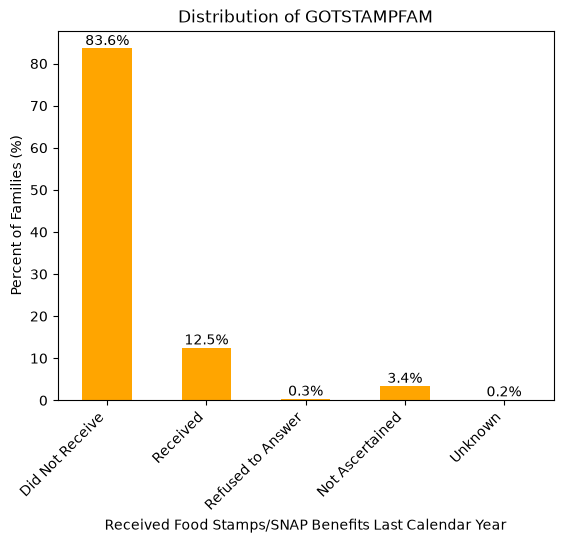

In [10]:
labels = {10:'Did Not Receive', 21:'Received', 70:'Refused to Answer',
          80:'Not Ascertained', 90:'Unknown'}
pct = (df['GOTSTAMPFAM'].value_counts(normalize=True)*100).sort_index()
pct.index = pct.index.map(labels)

ax = pct.plot.bar(color='orange')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Received Food Stamps/SNAP Benefits Last Calendar Year')
plt.ylabel('Percent of Families (%)')
plt.title('Distribution of GOTSTAMPFAM')
plt.show()